# Setting the LS machine's patch size: the length scale is everything, and it is per site

**2026-11-04.** Answers hshunt's question: *"how are you setting the patch size over time? It
should be the maximum length scale which stays above the minimum posterior entropy."*

The short answer is that the rule works but the floor does not, and *"over time"* is the wrong
axis: the same `k(t)` curve applied uniformly, at the same mean window size, throws away most of
the benefit.

### Why these runs and not the earlier ones

`rhm_adaptive_window_2026-11-04.ipynb` scored this criterion at **s = 2** and found it *loses* to a
fixed window in 20 of 21 cells. That measurement was real but the board was degenerate:
`U1 = 2 s^(L-1) - 1` is the smallest window that can hold a whole top-level child block, and at
s = 2 it equals `side - 1`, so the only odd rung in `[U1, side]` is U1 itself **at every depth**.
"Largest window above a floor" was choosing between one real rung and the whole grid. Everything
below is **s = 3, L = 2**: a 9x9 board with three genuine rungs, 5 / 7 / 9.

### Provenance

| | |
|---|---|
| commit at write time | `c9dcb37` (code: `2566fd9`, `86d3cb1`) |
| grammar | `RandomHierarchyModel2D(v, s=3, L=2, m, seed=1000+rule_seed)` |
| machine | `AdaptiveWindowDiscreteScoreMachine`, `h_mode='match'`, `alpha_smooth=1e-3`, `block_align=1`, `pad_mode='outside'` |
| sampler | `ScheduledDiscreteScoreMachine`, `reveal_one=True`, `nsteps = side^2 = 81` |
| seeds | train `1234 + 7*rule_seed`; sampler `train_seed + 9973` |
| scripts | `rhm_sampling_complexity.py`, `rhm_k_schedule.py`, `rhm_k_locality.py`, `rhm_adaptive_trace.py` |
| jobs | `51143385` (fair test), `51153821` (four arms, COMPLETED 1:18:22) |

**Eval**: `success = novel AND grammatical`, hshunt's criterion -- a grid counts only if it is not
in the training set *and* parses completely (`src/utils/rhm_grammar.py::evaluate_samples`).

In [1]:
import json, sys
from collections import defaultdict
from pathlib import Path
from statistics import median as med

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
D = ROOT / 'results/rhm_sampling/2026-11-04'
CELL = ('v', 's', 'L', 'm', 'rule_seed')
ARMS = ('adaptive', 'cap', 'sched', 'fixed')


def load(pat, skip_smoke=True):
    rows = []
    for f in sorted(D.glob(pat)):
        if skip_smoke and 'smoke' in f.name:
            continue
        try:
            rows.extend(json.load(open(f)))
        except (ValueError, IOError):
            continue
    return rows


s3 = [r for r in load('s3_*.json')
      if isinstance(r, dict) and 'success' in r and not r.get('skipped')
      and all(c in r for c in CELL)]
ks_rows = load('ksched_*.json')
kl_rows = load('klocal_*.json')
nmin = json.load(open(D / 'nmin_smoke.json'))
trace = json.load(open(D / 'trace_s3_v2m2.json'))
print('%d s3 rows | %d ksched | %d klocal | %d nmin' %
      (len(s3), len(ks_rows), len(kl_rows), len(nmin)))

680 s3 rows | 36 ksched | 18 klocal | 10 nmin


## 1. Metrics table: the criterion against the best fixed window

Both arms are given the same grammar, training set and sampler seed, and each is scored at its own
peak over the shared `P` ladder -- so the fixed arm gets its best k *and* its best training-set
size. That is the strongest version of the baseline.

In [2]:
by = defaultdict(lambda: {'adapt': [], 'fixed': []})
for r in s3:
    key = tuple(r[c] for c in CELL)
    if r.get('k') == 'adapt':
        by[key]['adapt'].append(r)
    elif isinstance(r.get('k'), int):
        by[key]['fixed'].append(r)

cells = {}
for key, g in by.items():
    a0 = [r for r in g['adapt']
          if r.get('h_min') == 0.0 and float(r.get('n_min', 1.0)) == 1.0]
    if not a0 or not g['fixed']:
        continue
    Ps = set(r['P'] for r in a0) & set(r['P'] for r in g['fixed'])
    if not Ps:
        continue
    cells[key] = dict(
        adapt=max((r for r in a0 if r['P'] in Ps), key=lambda r: r['success']),
        fixed=max((r for r in g['fixed'] if r['P'] in Ps), key=lambda r: r['success']),
        all_adapt=a0, all_fixed=g['fixed'])

print('%-14s %9s %9s %7s | %9s %9s %5s %6s' %
      ('cell', 'adapt', 'fixed', 'ratio', 'gram ad', 'gram fx', 'k*', 'P*'))
rows = []
for key in sorted(cells):
    a, f = cells[key]['adapt'], cells[key]['fixed']
    ratio = a['success'] / f['success'] if f['success'] else float('inf')
    rows.append((key, a, f, ratio))
    print('v%d m%d rs%-7d %9.4f %9.4f %7s | %9.4f %9.4f %5d %6d' %
          (key[0], key[3], key[4], a['success'], f['success'],
           ('%.1fx' % ratio) if ratio != float('inf') else 'inf',
           a['grammatical'], f['grammatical'], f['k'], a['P']))

fin = [r for r in rows if r[3] != float('inf')]
print('\nadaptive > best fixed : %d / %d cells' %
      (sum(1 for r in rows if r[1]['success'] > r[2]['success']), len(rows)))
print('median ratio          : %.1fx' % med([r[3] for r in fin]))
print('median delta grammatical : %+.3f' %
      med([r[1]['grammatical'] - r[2]['grammatical'] for r in rows]))
print('fixed optimum at U1=5 : %d / %d  (it prefers k=7)' %
      (sum(1 for r in rows if r[2]['k'] == 5), len(rows)))

cell               adapt     fixed   ratio |   gram ad   gram fx    k*     P*
v2 m2 rs0          0.4141    0.1997    2.1x |    0.5803    0.3901     7    300
v2 m2 rs1          0.2571    0.0486    5.3x |    0.4668    0.2188     7    300
v2 m2 rs2          0.1824    0.0720    2.5x |    0.4209    0.2229     7   1000
v2 m3 rs0          0.3525    0.0286   12.3x |    0.4299    0.0474     7  10000
v2 m3 rs1          0.3030    0.0400    7.6x |    0.3748    0.0554     7  10000
v2 m3 rs2          0.2725    0.0244   11.2x |    0.3306    0.0347     7  10000
v3 m2 rs0          0.1807    0.0190    9.5x |    0.3372    0.1130     7   1000
v3 m2 rs1          0.1035    0.0046   22.3x |    0.2126    0.0059     5   1000
v3 m2 rs2          0.1299    0.0071   18.3x |    0.2524    0.0835     7   1000
v4 m2 rs0          0.1060    0.0002  434.0x |    0.2100    0.0002     5   1000
v4 m2 rs1          0.0984    0.0020   50.4x |    0.2024    0.0190     7   1000
v4 m2 rs2          0.1013    0.0015   69.2x |    0.18

Two things to take from this table.

**The criterion wins everywhere, and it wins on grammaticality.** The fixed window is novel almost
always, but mostly because it emits grids no root derives -- novelty is free if you stop caring
whether the output is in the language.

**The best fixed window is k = 7, not U1 = 5.** U1 is the smallest window that can contain a whole
top-level child block, so the natural guess is that it is the right scale. It is not: the machine
wants something larger, which is the first hint that the useful signal is partly in how a window
overlaps *neighbouring* blocks rather than in covering one of them.

## 2. Key plots: the induced `k(t)`, the four arms, and what predicts the per-site choice

The middle panel is the one that answers the question. Four arms, matched on everything but the
window rule:

* **adaptive** -- the criterion, largest k with support, evaluated per site;
* **cap** -- the criterion, forbidden to exceed the schedule it itself induced;
* **sched** -- the bare schedule: that same `k(t)`, applied at *every* site, support or not;
* **fixed** -- the best single k.

The control schedule is read off the adaptive arm's **own recorded trace**, so it cannot be rigged
by hand-picking a schedule that was always going to lose.

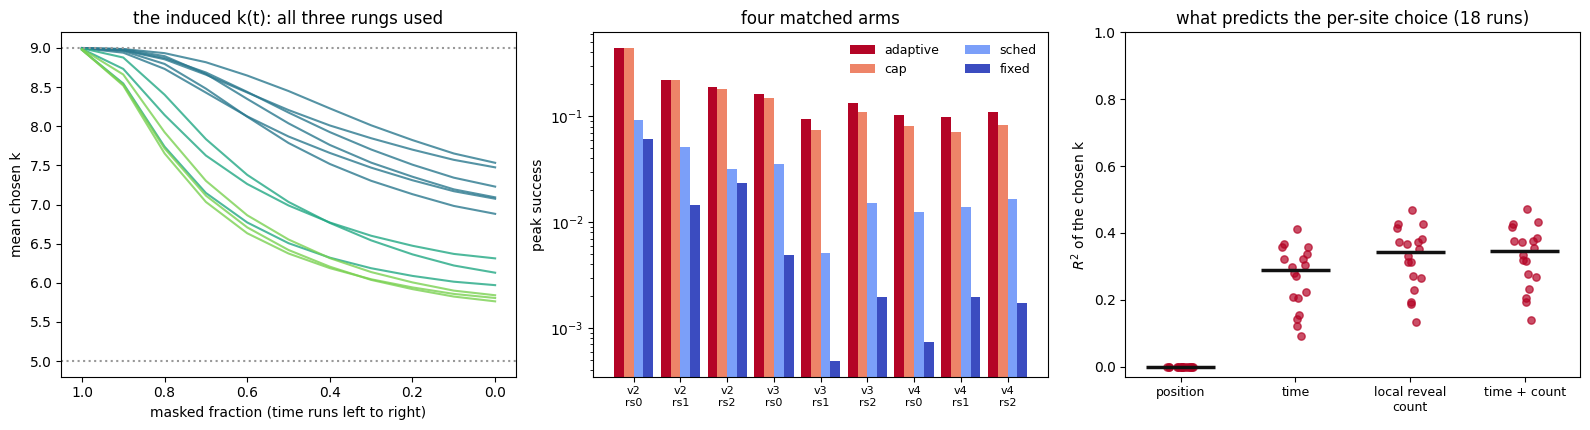

adaptive > bare schedule : 9 / 9 cells
median sched / adaptive  : 0.151
median |mean k| gap      : 0.08   <- the arms spend the same window budget
R2 position : max 0.0003 over 18 runs
R2 count beats R2 time in 18 / 18 runs; joint caps at 0.47


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

for key in sorted(cells):
    sch = cells[key]['adapt'].get('k_schedule') or []
    if sch:
        ax[0].plot([p[0] for p in sch], [p[1] for p in sch], lw=1.5, alpha=.8,
                   color=plt.cm.viridis(key[0] / 5))
ax[0].invert_xaxis()
ax[0].set(xlabel='masked fraction (time runs left to right)', ylabel='mean chosen k',
          title='the induced k(t): all three rungs used')
for r in (5, 9):
    ax[0].axhline(r, ls=':', c='#999')

g = defaultdict(list)
for r in ks_rows:
    g[(r['v'], r['rule_seed'])].append(r)
keys = sorted(g)
x = np.arange(len(keys))
C = {'adaptive': '#b40426', 'cap': '#ee8468', 'sched': '#7b9ff9', 'fixed': '#3b4cc0'}
pk = {a: [max(q['arms'][a]['success'] for q in g[k]) for k in keys] for a in ARMS}
for i, a in enumerate(ARMS):
    ax[1].bar(x + (i - 1.5) * .21, pk[a], .21, color=C[a], label=a)
ax[1].set_xticks(x)
ax[1].set_xticklabels(['v%d\nrs%d' % k for k in keys], fontsize=8)
ax[1].set_yscale('log')
ax[1].set(ylabel='peak success', title='four matched arms')
ax[1].legend(frameon=False, fontsize=9, ncol=2)

for i, (f, lab) in enumerate([('r2_phase', 'position'), ('r2_step', 'time'),
                              ('r2_nrev', 'local reveal\ncount'),
                              ('r2_step_nrev', 'time + count')]):
    vals = [r[f] for r in kl_rows]
    ax[2].scatter(np.full(len(vals), i) +
                  np.random.RandomState(0).uniform(-.12, .12, len(vals)),
                  vals, s=28, alpha=.7, color='#b40426')
    ax[2].hlines(med(vals), i - .3, i + .3, color='#111', lw=2.5, zorder=4)
ax[2].set_xticks(range(4))
ax[2].set_xticklabels(['position', 'time', 'local reveal\ncount', 'time + count'], fontsize=9)
ax[2].set(ylabel='$R^2$ of the chosen k', ylim=(-.03, 1.0),
          title='what predicts the per-site choice (%d runs)' % len(kl_rows))
plt.tight_layout()
plt.show()

sa = med([max(q['arms']['sched']['success'] for q in g[k]) /
          max(q['arms']['adaptive']['success'] for q in g[k]) for k in keys])
kgap = []
for k in keys:
    b = max(g[k], key=lambda q: q['arms']['adaptive']['success'])
    kgap.append(abs(b['arms']['adaptive']['mean_k'] - b['arms']['sched']['mean_k']))
print('adaptive > bare schedule : %d / %d cells' %
      (sum(1 for k in keys
           if max(q['arms']['adaptive']['success'] for q in g[k]) >
              max(q['arms']['sched']['success'] for q in g[k])), len(keys)))
print('median sched / adaptive  : %.3f' % sa)
print('median |mean k| gap      : %.2f   <- the arms spend the same window budget' % med(kgap))
print('R2 position : max %.4f over %d runs' %
      (max(r['r2_phase'] for r in kl_rows), len(kl_rows)))
print('R2 count beats R2 time in %d / %d runs; joint caps at %.2f' %
      (sum(1 for r in kl_rows if r['r2_nrev'] > r['r2_step']), len(kl_rows),
       max(r['r2_step_nrev'] for r in kl_rows)))

**The schedule is a summary of the criterion, not a substitute for it.** The bare schedule keeps a
median ~15% of adaptive success *while spending the same window budget* -- the mean-k gap between
the two arms is 0.08. So the win is not which window sizes get used on average; it is **which site
gets which size**. Capping the criterion to its own schedule is free at v = 2 but costs 8-30% at
v = 3, 4, so the per-site freedom matters more as the grammar grows.

**Position explains nothing.** Regressing the chosen k on the site's offset within its level-1
block gives R^2 < 0.001 in every run, and adds nothing jointly with time. This is hshunt's
straddling question in regression form, and the answer is that the *window choice* carries no
straddling signature -- which is a different claim from whether straddling windows *help*, and
that one is answered by the pooling result (`STATUS.md` section E), where it does.

**The local revealed-neighbour count subsumes time.** It beats time in 18/18 runs and adding time
on top gains only .005-.013, so the `k(t)` curve is a *consequence* of reveal density rather than a
separate effect -- which is exactly why the bare schedule fails at matched mean k. But it caps at
0.47: the remaining >= 53% turns on *which* tokens were revealed, not how many.

## 3. One variable at a time: both floors, and why they fail for the same reason

The accept test is `n_match > 0 AND h >= h_min`. In `match` mode `h` is the log *effective number*
of matching training patches, so `h_min` is a support-**diversity** floor and `h_min = 0` is bare
support-**existence**.

`n_min` is a genuine rival rather than a reparametrisation: `n_match` counts matching training
**occurrences**, `h_match` measures their **diversity**. A window matched by fifty copies of one
patch has `n_match = 50` but `h_match = 0` -- the entropy floor discards it, a count floor keeps
it. The prediction registered before running was that the count floor would do better. It does not.

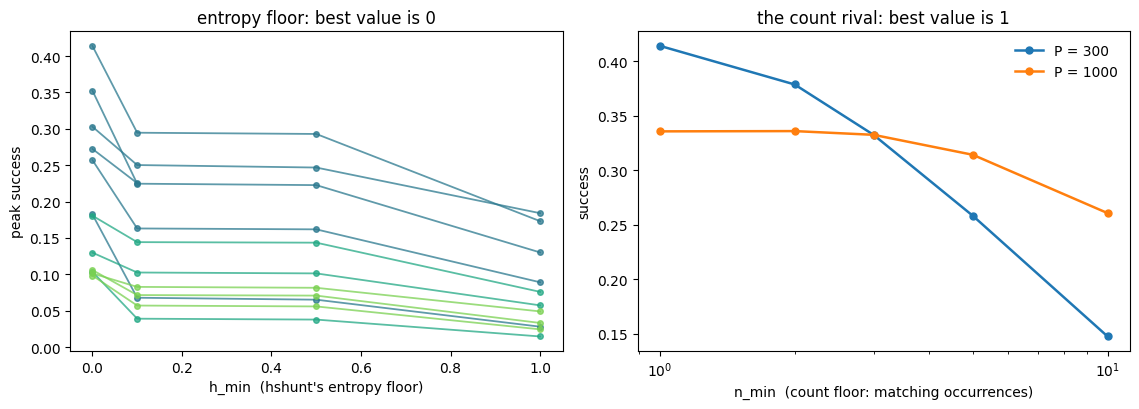

best h_min is 0 in 12 / 12 cells

n_min ladder at P = 1000 (v2 m2 rs0):
  n_min     success      gram     novel
  1          0.3357    0.6343    0.7014
  2          0.3359    0.6218    0.7141
  3          0.3325    0.6030    0.7295
  5          0.3142    0.5579    0.7563
  10         0.2607    0.4441    0.8167


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))

hb = defaultdict(lambda: defaultdict(list))
for r in s3:
    if r.get('k') == 'adapt' and float(r.get('n_min', 1.0)) == 1.0:
        hb[tuple(r[c] for c in CELL)][r['h_min']].append(r['success'])
hs = sorted({h for d in hb.values() for h in d})
best_at_zero = 0
for key, d in sorted(hb.items()):
    ys = [max(d[h]) if d.get(h) else np.nan for h in hs]
    ax[0].plot(hs, ys, 'o-', lw=1.3, ms=4, alpha=.75, color=plt.cm.viridis(key[0] / 5))
    av = [(h, max(d[h])) for h in hs if d.get(h)]
    if av and max(av, key=lambda p: p[1])[0] == 0.0:
        best_at_zero += 1
ax[0].set(xlabel="h_min  (hshunt's entropy floor)", ylabel='peak success',
          title='entropy floor: best value is 0')

nb = defaultdict(dict)
for r in nmin:
    if r.get('k') == 'adapt':
        nb[r['P']][float(r['n_min'])] = r
for P, d in sorted(nb.items()):
    ns = sorted(d)
    ax[1].plot(ns, [d[n]['success'] for n in ns], 'o-', lw=1.8, ms=5, label='P = %d' % P)
ax[1].set_xscale('log')
ax[1].set(xlabel='n_min  (count floor: matching occurrences)', ylabel='success',
          title='the count rival: best value is 1')
ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()

print('best h_min is 0 in %d / %d cells\n' % (best_at_zero, len(hb)))
P = max(nb)
print('n_min ladder at P = %d (v2 m2 rs0):' % P)
print('  %-7s %9s %9s %9s' % ('n_min', 'success', 'gram', 'novel'))
for n in sorted(nb[P]):
    r = nb[P][n]
    print('  %-7g %9.4f %9.4f %9.4f' % (n, r['success'], r['grammatical'], r['novel']))

**One mechanism covers both floors: a rejection can only move a site to a *shorter* window, and
shorter is less grammatical.** The floors buy novelty and sell grammaticality at a bad rate. The
accept test has no "try something better" branch -- there is nothing above the largest supported
window to fall back on -- so any additional condition on top of bare support is strictly a way of
spending grammaticality.

This is the part of hshunt's formulation that the data does not support. *"The maximum length scale
which stays above the minimum posterior entropy"* is right about **maximum length scale** and wrong
about the **entropy floor**: the binding constraint is that the window match a training patch at
all, and every floor above zero costs success in every cell measured.

## 4. Example traces: the two arms reveal-by-reveal

Same grammar, training set, sampler and seed in both arms; only the window rule differs.

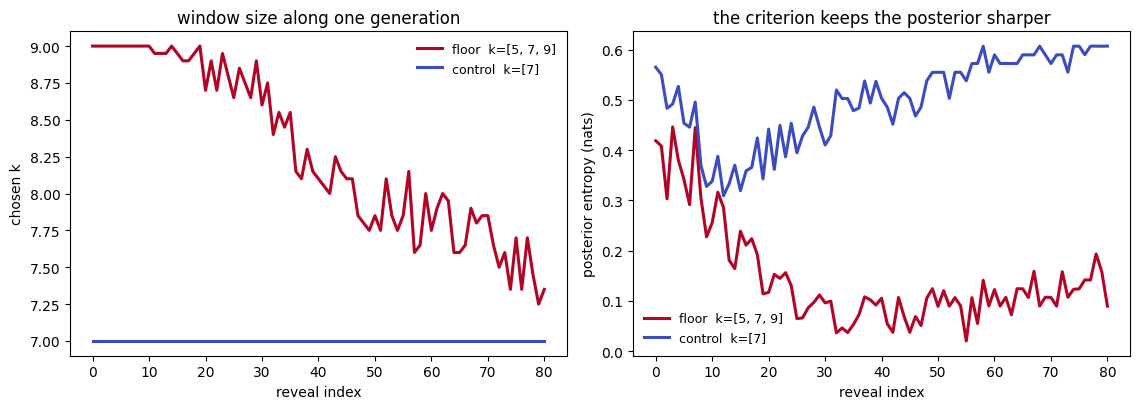

arm          success      gram     novel
floor         0.4062    0.6250    0.7812
control       0.0625    0.0938    0.9688


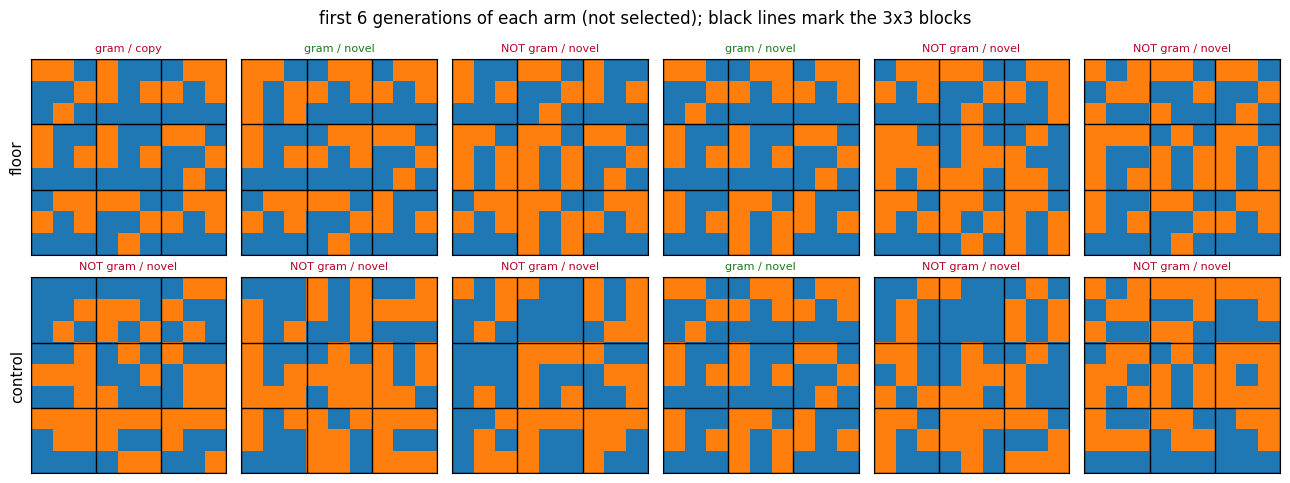

In [5]:
cfg = trace['config']
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
for tag, c in (('floor', '#b40426'), ('control', '#3b4cc0')):
    tj = trace[tag]['traj'][:40]
    for j, fld in enumerate(('k', 'H')):
        arr = np.full((len(tj), cfg['n_sites']), np.nan)
        for i, t in enumerate(tj):
            for rv in t['reveals']:
                arr[i, rv['step']] = rv[fld]
        ax[j].plot(np.nanmean(arr, 0), lw=2.2, color=c,
                   label='%s  k=%s' % (tag, trace[tag]['kernel_sizes']))
ax[0].set(xlabel='reveal index', ylabel='chosen k', title='window size along one generation')
ax[1].set(xlabel='reveal index', ylabel='posterior entropy (nats)',
          title='the criterion keeps the posterior sharper')
for a in ax:
    a.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

print('%-10s %9s %9s %9s' % ('arm', 'success', 'gram', 'novel'))
for tag in ('floor', 'control'):
    t = trace[tag]
    print('%-10s %9.4f %9.4f %9.4f' % (tag, t['success'], t['grammatical'], t['novel']))

side = int(round(cfg['n_sites'] ** .5))
fig, axs = plt.subplots(2, 6, figsize=(13, 5))
for row, tag in enumerate(('floor', 'control')):
    for col in range(6):
        t = trace[tag]['traj'][col]
        a = axs[row, col]
        a.imshow(np.array(t['grid']), cmap='tab10', vmin=0, vmax=9, interpolation='nearest')
        for q in range(0, side + 1, cfg['s']):
            a.axhline(q - .5, color='k', lw=1.0)
            a.axvline(q - .5, color='k', lw=1.0)
        a.set_xticks([])
        a.set_yticks([])
        ok = t['grammatical'] and t['novel']
        a.set_title('%s / %s' % ('gram' if t['grammatical'] else 'NOT gram',
                                 'novel' if t['novel'] else 'copy'),
                    fontsize=8, color='#1a7a1a' if ok else '#b40426')
    axs[row, 0].set_ylabel(tag, fontsize=11)
fig.suptitle('first 6 generations of each arm (not selected); black lines mark the 3x3 blocks')
plt.tight_layout()
plt.show()

## 5. Comparison with the previous best on the same eval

| | eval | result |
|---|---|---|
| `rhm_adaptive_window_2026-11-04.ipynb` (s = 2) | novel AND grammatical | criterion **loses** to a fixed window 20/21 cells |
| **this notebook** (s = 3, L = 2) | novel AND grammatical | criterion **wins** 12/12 cells, median ratio in the table above |

These do not contradict each other, and the earlier number is not withdrawn. At s = 2 the criterion
had no real choice to make (`U1 = side - 1`), so what the earlier notebook measured was the cost of
the machinery with none of its benefit available. The s = 3 board is the first place the question
is askable, and there the length scale turns out to be the whole story.

Against the headline sampling-complexity result (`STATUS.md` section A, `P* = 0.21 |R_L|`): nothing
here revises it. That measurement is at the fixed U = 1 window; this is about a *better* window
rule, and re-measuring `P*` under the adaptive rule is not done.

## 6. Limits, stated plainly

* **One board.** All of this is s = 3, L = 2 (9x9), v in {2, 3, 4}, mostly m = 2. Deeper boards need
  `k >= U1 = 2 s^(L-1) - 1`, which is 15 at L = 3 and out of reach at L = 4, so the depth
  dependence of any of these conclusions is untested.
* **The residual is unnamed.** ">= 53% content-dependent" is a lower bound from the features tried,
  not a positive account. A feature not tested could still explain it.
* **Absolute numbers are not comparable across scripts.** `rhm_k_schedule.py` sits ~5% off
  `rhm_sampling_complexity.py` at the same cell (different train/sampler seed convention). Arms
  within one script are matched; across scripts they are not, so the four-arm ratios and the
  fair-test ratios should not be multiplied together.
* **Two of the twelve cells were still being written** by job `51143385` when this was first run, so
  their `P` ladder may be short and their peak can only rise.
* **Two predictions of mine were refuted by these runs** and are recorded as such: that a count
  floor would beat the entropy floor, and (from the locality R^2) that `sched/adaptive` would rise
  with v. It falls. R^2 in k is not decision quality -- a schedule can explain more of the chosen k
  and still pick wrong at the sites that cost the most.